# 06 — Customer Lapse Prediction

## Objective
Develop a predictive model to identify customers at risk of becoming inactive based on their historical purchasing behaviour.

## Business Problem
The sales team has limited capacity for customer outreach. A predictive model can help prioritise customers who are more likely to stop purchasing, allowing the team to intervene before the relationship is lost.

## Analytical Approach
1. Define customer lapse using a future period of purchase inactivity.
2. Construct customer-level behavioural features using historical transactions.
3. Create labelled training and testing datasets using chronological observation periods.
4. Train and compare classification models.
5. Evaluate model performance using appropriate classification metrics.
6. Identify high-risk customers for sales outreach.

## Important Considerations
- Only information available before each observation date will be used as model features.
- Future purchasing behaviour will be used only to construct the target variable.
- A time-based validation approach will be used to reduce temporal data leakage.
- Predictions indicate lapse risk, not confirmed customer churn.

In [26]:
import pandas as pd
import numpy as np

DATA_FILE = "../data/clean/transactions_clean.parquet"

transactions = pd.read_parquet(DATA_FILE)

# Reconstruct transaction value
transactions["line_value"] = (
    transactions["Quantity"] * transactions["Price"]
)

# Identify valid purchase transactions
purchase_rows = transactions[
    transactions["Customer ID"].notna()
    & (~transactions["is_cancellation"])
    & (transactions["line_type"] == "product")
].copy()

print("Total transaction rows:", len(transactions))
print("Valid purchase rows:", len(purchase_rows))
print("Unique purchasing customers:",
      purchase_rows["Customer ID"].nunique())

print("\nData coverage:")
print("Start date:", transactions["InvoiceDate"].min())
print("End date:", transactions["InvoiceDate"].max())

Total transaction rows: 1041449
Valid purchase rows: 788249
Unique purchasing customers: 5853

Data coverage:
Start date: 2009-12-01 07:45:00
End date: 2011-12-09 12:50:00


In [27]:
# Define observation dates
snapshot_dates = pd.to_datetime([
    "2010-12-01",
    "2011-03-01",
    "2011-06-01",
    "2011-09-01"
])

# Define prediction horizon
prediction_days = 90
history_days = 365

# Check whether each snapshot has sufficient historical
# and future transaction coverage
for snapshot in snapshot_dates:
    history_start = snapshot - pd.Timedelta(days=history_days)
    outcome_end = snapshot + pd.Timedelta(days=prediction_days)

    print(f"\nSnapshot: {snapshot.date()}")
    print(f"History starts: {history_start.date()}")
    print(f"90-day outcome ends: {outcome_end.date()}")
    print(
        "Historical coverage available:",
        transactions["InvoiceDate"].min().date() <= history_start.date()
    )
    print(
        "Future outcome coverage available:",
        transactions["InvoiceDate"].max().date() >= outcome_end.date()
    )


Snapshot: 2010-12-01
History starts: 2009-12-01
90-day outcome ends: 2011-03-01
Historical coverage available: True
Future outcome coverage available: True

Snapshot: 2011-03-01
History starts: 2010-03-01
90-day outcome ends: 2011-05-30
Historical coverage available: True
Future outcome coverage available: True

Snapshot: 2011-06-01
History starts: 2010-06-01
90-day outcome ends: 2011-08-30
Historical coverage available: True
Future outcome coverage available: True

Snapshot: 2011-09-01
History starts: 2010-09-01
90-day outcome ends: 2011-11-30
Historical coverage available: True
Future outcome coverage available: True


In [28]:
# Aggregate valid product purchases to customer-invoice level
purchase_invoices = (
    purchase_rows.groupby(["Customer ID", "Invoice"])
    .agg(
        purchase_date=("InvoiceDate", "min"),
        purchase_value=("line_value", "sum"),
        products_purchased=("StockCode", "nunique")
    )
    .reset_index()
)

# Validate purchase-level dataset
print("Purchase invoice records:", len(purchase_invoices))
print(
    "Unique customers:",
    purchase_invoices["Customer ID"].nunique()
)
print(
    "Unique invoices:",
    purchase_invoices["Invoice"].nunique()
)

print("\nPurchase date range:")
print("Start:", purchase_invoices["purchase_date"].min())
print("End:", purchase_invoices["purchase_date"].max())

display(purchase_invoices.head())

Purchase invoice records: 36597
Unique customers: 5853
Unique invoices: 36597

Purchase date range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00


,Customer ID,Invoice,purchase_date,purchase_value,products_purchased
0,12346,499763,2010-03-02 13:08:00,27.05,5
1,12346,513774,2010-06-28 13:53:00,142.31,19
2,12346,541431,2011-01-18 10:01:00,77183.60,1
3,12347,529924,2010-10-31 14:20:00,611.53,40
4,12347,537626,2010-12-07 14:57:00,711.79,31


In [29]:
# Function to create customer features for one snapshot
def create_customer_features(snapshot):

    history_start = snapshot - pd.Timedelta(days=365)

    # Use only purchases in the preceding 365 days
    historical_data = purchase_invoices[
        (purchase_invoices["purchase_date"] >= history_start)
        & (purchase_invoices["purchase_date"] < snapshot)
    ].copy()

    # Aggregate historical behaviour by customer
    features = (
        historical_data.groupby("Customer ID")
        .agg(
            last_purchase_date=("purchase_date", "max"),
            first_purchase_date=("purchase_date", "min"),
            frequency=("Invoice", "nunique"),
            monetary=("purchase_value", "sum"),
            total_products=("products_purchased", "sum"),
            avg_basket_size=("products_purchased", "mean")
        )
        .reset_index()
    )

    # Derive additional behavioural features
    features["recency"] = (
        snapshot - features["last_purchase_date"]
    ).dt.days

    features["avg_order_value"] = (
        features["monetary"] / features["frequency"]
    )

    features["customer_tenure"] = (
        features["last_purchase_date"]
        - features["first_purchase_date"]
    ).dt.days

    # Store snapshot date
    features["snapshot_date"] = snapshot

    return features


# Create features for all four snapshots
snapshot_features = pd.concat(
    [
        create_customer_features(snapshot)
        for snapshot in snapshot_dates
    ],
    ignore_index=True
)

print("Total customer-snapshot records:", len(snapshot_features))
print(
    "Unique customers:",
    snapshot_features["Customer ID"].nunique()
)
print(
    "Snapshot dates:",
    snapshot_features["snapshot_date"].nunique()
)

display(snapshot_features.head())

Total customer-snapshot records: 17147
Unique customers: 5224
Snapshot dates: 4


,Customer ID,last_purchase_date,first_purchase_date,frequency,monetary,total_products,avg_basket_size,recency,avg_order_value,customer_tenure,snapshot_date
0,12346,2010-06-28 13:53:00,2010-03-02 13:08:00,2,169.36,24,12.0,155,84.68,118,2010-12-01
1,12347,2010-10-31 14:20:00,2010-10-31 14:20:00,1,611.53,40,40.0,30,611.53,0,2010-12-01
2,12348,2010-09-27 14:59:00,2010-09-27 14:59:00,1,221.16,19,19.0,64,221.16,0,2010-12-01
3,12349,2010-10-28 08:23:00,2010-04-29 13:20:00,2,2221.14,100,50.0,33,1110.57,181,2010-12-01
4,12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,21,21.0,1,300.93,0,2010-12-01


In [30]:
# Function to label customers based on future purchase activity
def create_lapse_labels(snapshot):

    outcome_end = snapshot + pd.Timedelta(days=90)

    # Purchases during the next 90 days
    future_purchases = purchase_invoices[
        (purchase_invoices["purchase_date"] >= snapshot)
        & (purchase_invoices["purchase_date"] < outcome_end)
    ]

    # Identify customers who purchased during the outcome period
    purchased_customers = set(
        future_purchases["Customer ID"].unique()
    )

    # Customers with no future purchase are labelled as lapsed
    labels = snapshot_features.loc[
        snapshot_features["snapshot_date"] == snapshot,
        ["Customer ID", "snapshot_date"]
    ].copy()

    labels["lapse"] = (
        ~labels["Customer ID"].isin(purchased_customers)
    ).astype(int)

    return labels


# Generate labels for all four snapshots
snapshot_labels = pd.concat(
    [
        create_lapse_labels(snapshot)
        for snapshot in snapshot_dates
    ],
    ignore_index=True
)

# Attach labels to customer features
model_data = snapshot_features.merge(
    snapshot_labels,
    on=["Customer ID", "snapshot_date"],
    how="inner"
)

# Validate target variable
print("Total labelled records:", len(model_data))
print("\nLapse distribution:")
display(
    model_data["lapse"]
    .value_counts()
    .rename(index={0: "Not Lapsed", 1: "Lapsed"})
    .to_frame("Customers")
)

print("\nLapse rate: {:.2f}%".format(
    model_data["lapse"].mean() * 100
))

print("\nLapse rate by snapshot:")
display(
    model_data.groupby("snapshot_date")["lapse"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Customers",
        "sum": "Lapsed Customers",
        "mean": "Lapse Rate"
    })
    .assign(
        **{"Lapse Rate": lambda x: x["Lapse Rate"] * 100}
    )
    .round(2)
)

Total labelled records: 17147

Lapse distribution:


,Customers
lapse,
Lapsed,10443
Not Lapsed,6704



Lapse rate: 60.90%

Lapse rate by snapshot:


,Customers,Lapsed Customers,Lapse Rate
snapshot_date,,,
2010-12-01,4239,2832,66.81
2011-03-01,4260,2689,63.12
2011-06-01,4324,2740,63.37
2011-09-01,4324,2182,50.46


In [31]:
# Check for duplicate customer-snapshot records
duplicate_records = model_data.duplicated(
    subset=["Customer ID", "snapshot_date"]
).sum()

# Check missing values
missing_values = model_data.isna().sum()

# Check target values
target_values = sorted(model_data["lapse"].unique())

print("Total records:", len(model_data))
print("Duplicate customer-snapshot records:", duplicate_records)
print("Missing values across columns:")
display(missing_values.to_frame("Missing Values"))

print("Target classes:", target_values)

# Check feature statistics
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_order_value",
    "total_products",
    "avg_basket_size",
    "customer_tenure"
]

display(model_data[feature_columns].describe().round(2))

Total records: 17147
Duplicate customer-snapshot records: 0
Missing values across columns:


,Missing Values
Customer ID,0
last_purchase_date,0
first_purchase_date,0
frequency,0
monetary,0
total_products,0
avg_basket_size,0
recency,0
avg_order_value,0
customer_tenure,0


Target classes: [0, 1]


,recency,frequency,monetary,avg_order_value,total_products,avg_basket_size,customer_tenure
count,17147.00,17147.00,17147.00,17147.00,17147.00,17147.00,17147.00
mean,120.39,4.18,1913.02,387.11,85.94,21.52,121.08
std,103.24,7.35,7800.20,857.19,180.77,18.42,124.73
min,0.00,1.00,1.55,1.55,1.00,1.00,0.00
25%,28.00,1.00,302.70,179.54,17.00,9.75,0.00
50%,92.00,2.00,658.18,288.15,40.00,17.14,85.00
75%,195.00,5.00,1600.89,424.81,95.00,27.50,235.00
max,364.00,181.00,321329.74,77183.60,5325.00,230.00,364.00


In [32]:
# Define training and testing periods
train_data = model_data[
    model_data["snapshot_date"] < pd.Timestamp("2011-09-01")
].copy()

test_data = model_data[
    model_data["snapshot_date"] == pd.Timestamp("2011-09-01")
].copy()

# Define model features
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_order_value",
    "total_products",
    "avg_basket_size",
    "customer_tenure"
]

# Separate features and target
X_train = train_data[feature_columns]
y_train = train_data["lapse"]

X_test = test_data[feature_columns]
y_test = test_data["lapse"]

# Validate split
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining lapse rate: {:.2f}%".format(
    y_train.mean() * 100
))

print("Testing lapse rate: {:.2f}%".format(
    y_test.mean() * 100
))

print("\nTraining snapshots:")
print(sorted(train_data["snapshot_date"].unique()))

print("\nTesting snapshot:")
print(test_data["snapshot_date"].unique())

Training records: 12823
Testing records: 4324

Training lapse rate: 64.42%
Testing lapse rate: 50.46%

Training snapshots:
[Timestamp('2010-12-01 00:00:00'), Timestamp('2011-03-01 00:00:00'), Timestamp('2011-06-01 00:00:00')]

Testing snapshot:
<DatetimeArray>
['2011-09-01 00:00:00']
Length: 1, dtype: datetime64[ns]


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Features with highly skewed distributions
skewed_features = [
    "frequency",
    "monetary",
    "avg_order_value",
    "total_products",
    "avg_basket_size"
]

regular_features = [
    "recency",
    "customer_tenure"
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "log_scaled",
            Pipeline([
                ("log", FunctionTransformer(np.log1p)),
                ("scale", StandardScaler())
            ]),
            skewed_features
        ),
        (
            "regular_scaled",
            StandardScaler(),
            regular_features
        )
    ]
)

# Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train majority-class baseline
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Generate predictions
dummy_predictions = dummy_model.predict(X_test)
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate both models
results = pd.DataFrame([
    {
        "Model": "Dummy Baseline",
        "Accuracy": accuracy_score(y_test, dummy_predictions),
        "Precision": precision_score(y_test, dummy_predictions, zero_division=0),
        "Recall": recall_score(y_test, dummy_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, dummy_predictions, zero_division=0)
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, logistic_predictions),
        "Precision": precision_score(y_test, logistic_predictions),
        "Recall": recall_score(y_test, logistic_predictions),
        "F1 Score": f1_score(y_test, logistic_predictions),
        "ROC-AUC": roc_auc_score(y_test, logistic_probabilities)
    }
])

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Baseline,0.505,0.505,1.000,0.671,NaN
1,Logistic Regression,0.695,0.658,0.827,0.733,0.767


In [34]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Evaluate Random Forest
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(y_test, rf_predictions),
    "Recall": recall_score(y_test, rf_predictions),
    "F1 Score": f1_score(y_test, rf_predictions),
    "ROC-AUC": roc_auc_score(y_test, rf_probabilities)
}

print(pd.DataFrame([rf_results]).round(3).to_string(index=False))

        Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Random Forest     0.693      0.644   0.875     0.742    0.762


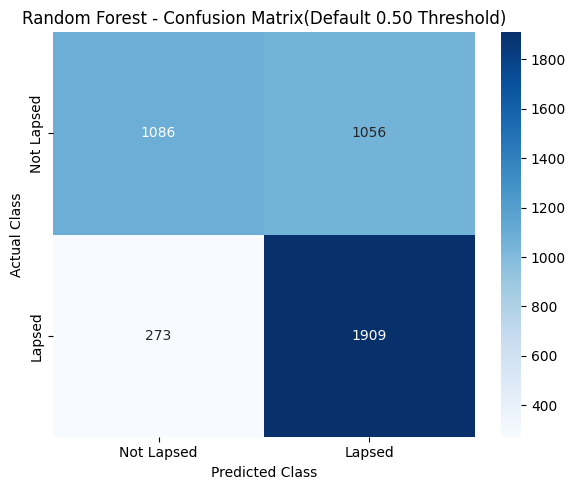


Classification Report:
              precision    recall  f1-score   support

  Not Lapsed       0.80      0.51      0.62      2142
      Lapsed       0.64      0.87      0.74      2182

    accuracy                           0.69      4324
   macro avg       0.72      0.69      0.68      4324
weighted avg       0.72      0.69      0.68      4324



In [35]:
# Confusion matrix for Random Forest
import matplotlib.pyplot as plt
import seaborn as sns
rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Lapsed", "Lapsed"],
    yticklabels=["Not Lapsed", "Lapsed"]
)

plt.title("Random Forest - Confusion Matrix(Default 0.50 Threshold)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Not Lapsed", "Lapsed"]
    )
)

,Feature,Importance
2,monetary,0.2101
1,frequency,0.1885
6,customer_tenure,0.1689
0,recency,0.1462
4,total_products,0.1221
3,avg_order_value,0.0927
5,avg_basket_size,0.0715


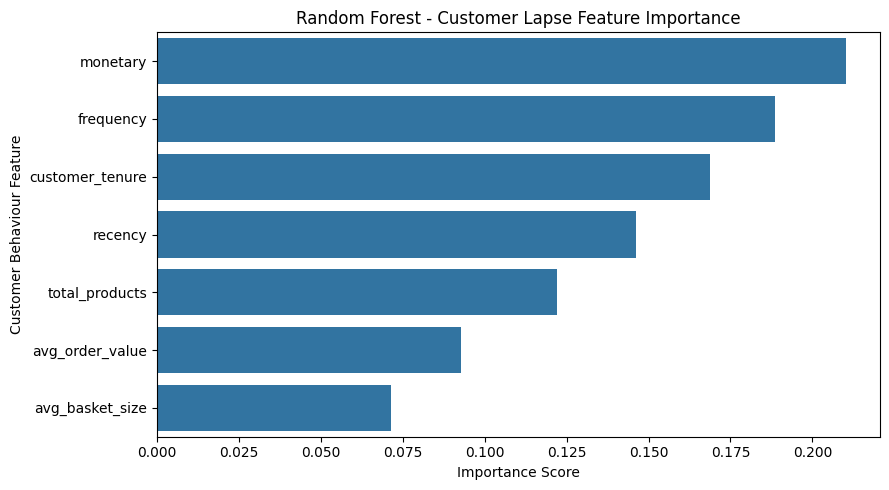

In [36]:
# Extract feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.round(4))

# Plot feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Customer Lapse Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Customer Behaviour Feature")

plt.tight_layout()
plt.show()

In [37]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the untouched test set
permutation_results = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": permutation_results.importances_mean,
    "Importance Std": permutation_results.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
)

display(permutation_importance_df.round(4))

,Feature,Importance Mean,Importance Std
0,recency,0.0146,0.0030
2,monetary,0.0099,0.0027
6,customer_tenure,0.0076,0.0024
1,frequency,0.0074,0.0020
4,total_products,0.0017,0.0014
3,avg_order_value,0.0001,0.0013
5,avg_basket_size,-0.0023,0.0014


In [38]:
# Separate training and validation snapshots
validation_train = model_data[
    model_data["snapshot_date"] < pd.Timestamp("2011-06-01")
]

validation_data = model_data[
    model_data["snapshot_date"] == pd.Timestamp("2011-06-01")
]

X_val_train = validation_train[feature_columns]
y_val_train = validation_train["lapse"]

X_val = validation_data[feature_columns]
y_val = validation_data["lapse"]

# Train temporary Random Forest
validation_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

validation_model.fit(X_val_train, y_val_train)

# Predict validation probabilities
validation_probabilities = (
    validation_model.predict_proba(X_val)[:, 1]
)

# Compare thresholds on validation data
validation_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Customers Flagged": predictions.sum(),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

validation_comparison = pd.DataFrame(validation_results)

display(validation_comparison.round(3))

,Threshold,Customers Flagged,Precision,Recall,F1 Score
0,0.3,3617,0.723,0.955,0.823
1,0.4,3361,0.748,0.918,0.824
2,0.5,3064,0.776,0.868,0.819
3,0.6,2630,0.805,0.773,0.789
4,0.7,1981,0.833,0.602,0.699
5,0.8,1000,0.878,0.320,0.470


In [39]:
# Retrain final Random Forest on all training snapshots
final_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(X_train, y_train)

# Generate test probabilities
final_probabilities = (
    final_rf_model.predict_proba(X_test)[:, 1]
)

# Apply validation-selected threshold
final_threshold = 0.40

final_predictions = (
    final_probabilities >= final_threshold
).astype(int)

# Evaluate final model
final_results = {
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(y_test, final_predictions),
    "Recall": recall_score(y_test, final_predictions),
    "F1 Score": f1_score(y_test, final_predictions),
    "ROC-AUC": roc_auc_score(y_test, final_probabilities),
    "Customers Flagged": final_predictions.sum()
}

display(pd.DataFrame([final_results]).round(3))

print("\nFinal Classification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Not Lapsed", "Lapsed"]
    )
)

,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Customers Flagged
0,0.4,0.673,0.617,0.926,0.741,0.762,3272



Final Classification Report:
              precision    recall  f1-score   support

  Not Lapsed       0.85      0.42      0.56      2142
      Lapsed       0.62      0.93      0.74      2182

    accuracy                           0.67      4324
   macro avg       0.73      0.67      0.65      4324
weighted avg       0.73      0.67      0.65      4324



In [40]:
# Create customer-level prediction output
lapse_predictions = test_data[
    [
        "Customer ID",
        "recency",
        "frequency",
        "monetary",
        "avg_order_value",
        "customer_tenure"
    ]
].copy()

# Add predicted probabilities and classifications
lapse_predictions["lapse_probability"] = final_probabilities

lapse_predictions["predicted_lapse"] = final_predictions

# Convert probability into percentage
lapse_predictions["lapse_probability_pct"] = (
    lapse_predictions["lapse_probability"] * 100
).round(2)

# Sort customers by predicted lapse probability
lapse_predictions = lapse_predictions.sort_values(
    "lapse_probability",
    ascending=False
).reset_index(drop=True)

print("Total customers scored:", len(lapse_predictions))

print("\nPredicted lapse distribution:")
display(
    lapse_predictions["predicted_lapse"]
    .value_counts()
    .rename(index={0: "Not Flagged", 1: "Flagged for Retention"})
    .to_frame("Customers")
)

print("\nTop 10 highest-risk customers:")
display(lapse_predictions.head(10))

Total customers scored: 4324

Predicted lapse distribution:


,Customers
predicted_lapse,
Flagged for Retention,3272
Not Flagged,1052



Top 10 highest-risk customers:


,Customer ID,recency,frequency,monetary,avg_order_value,customer_tenure,lapse_probability,predicted_lapse,lapse_probability_pct
0,13030,268,1,427.74,427.74,0,0.964706,1,96.47
1,15879,304,1,424.28,424.28,0,0.963112,1,96.31
2,14087,304,1,415.11,415.11,0,0.961430,1,96.14
3,16738,197,1,3.75,3.75,0,0.960629,1,96.06
4,15940,211,1,35.80,35.80,0,0.957852,1,95.79
5,17269,285,1,537.46,537.46,0,0.956190,1,95.62
6,14589,271,1,39.75,39.75,0,0.955238,1,95.52
7,15915,301,1,429.00,429.00,0,0.954991,1,95.50
8,14090,224,1,76.32,76.32,0,0.954919,1,95.49
9,16355,275,1,416.35,416.35,0,0.954848,1,95.48


In [41]:
# Define the historical cut-off for September 2011 predictions
rfm_cutoff = pd.Timestamp("2011-09-01")

# Keep only transactions available before the prediction date
historical_transactions = transactions[
    transactions["InvoiceDate"] < rfm_cutoff
].copy()

print("Historical data cut-off:", rfm_cutoff)
print("Historical transaction rows:", len(historical_transactions))
print(
    "Last transaction included:",
    historical_transactions["InvoiceDate"].max()
)

Historical data cut-off: 2011-09-01 00:00:00
Historical transaction rows: 820655
Last transaction included: 2011-08-31 17:45:00


In [42]:
# Identify valid purchase transactions before the cutoff
historical_purchase_rows = historical_transactions[
    historical_transactions["Customer ID"].notna()
    & (~historical_transactions["is_cancellation"])
    & (historical_transactions["line_type"] == "product")
].copy()

# Aggregate purchases to customer-invoice level
historical_purchase_invoices = (
    historical_purchase_rows
    .groupby(["Customer ID", "Invoice"])
    .agg(
        purchase_date=("InvoiceDate", "min"),
        purchase_value=("line_value", "sum")
    )
    .reset_index()
)

# Calculate recency and frequency
historical_rfm = (
    historical_purchase_invoices
    .groupby("Customer ID")
    .agg(
        last_purchase_date=("purchase_date", "max"),
        frequency=("Invoice", "nunique")
    )
    .reset_index()
)

historical_rfm["recency"] = (
    rfm_cutoff - historical_rfm["last_purchase_date"]
).dt.days

# Calculate net monetary value using product and adjustment rows
historical_monetary_rows = historical_transactions[
    historical_transactions["Customer ID"].notna()
    & historical_transactions["line_type"].isin(["product", "adjustment"])
].copy()

historical_monetary = (
    historical_monetary_rows
    .groupby("Customer ID")
    .agg(
        monetary_value=("line_value", "sum")
    )
    .reset_index()
)

# Combine historical RFM metrics
historical_rfm = historical_rfm.merge(
    historical_monetary,
    on="Customer ID",
    how="left"
)

historical_rfm["monetary_value"] = (
    historical_rfm["monetary_value"].round(2)
)

print("Historical RFM customers:", len(historical_rfm))
print("Unique customers:", historical_rfm["Customer ID"].nunique())
print("\nHistorical RFM summary:")
display(
    historical_rfm[
        ["recency", "frequency", "monetary_value"]
    ].describe().round(2)
)

print(
    "\nMissing values:",
    historical_rfm[
        ["recency", "frequency", "monetary_value"]
    ].isna().sum().to_dict()
)

Historical RFM customers: 5224
Unique customers: 5224

Historical RFM summary:


,recency,frequency,monetary_value
count,5224.00,5224.00,5224.00
mean,203.09,5.65,2479.19
std,170.78,11.07,11546.74
min,0.00,1.00,-3767.20
25%,49.00,1.00,310.05
50%,160.00,3.00,761.20
75%,317.00,6.00,1989.58
max,638.00,278.00,441260.54



Missing values: {'recency': 0, 'frequency': 0, 'monetary_value': 0}


In [43]:
# Recency scoring: lower recency receives a higher score
historical_rfm["R_score"] = pd.qcut(
    historical_rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency scoring using the original business rules
def score_frequency(value):
    if value == 1:
        return 1
    elif value == 2:
        return 2
    elif value <= 4:
        return 3
    elif value <= 8:
        return 4
    else:
        return 5

historical_rfm["F_score"] = (
    historical_rfm["frequency"].apply(score_frequency)
)

# Monetary scoring: score positive monetary values only
historical_rfm["M_score"] = 0

positive_mask = historical_rfm["monetary_value"] > 0

historical_rfm.loc[positive_mask, "M_score"] = pd.qcut(
    historical_rfm.loc[positive_mask, "monetary_value"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine RFM scores
historical_rfm["RFM_score"] = (
    historical_rfm["R_score"].astype(str)
    + historical_rfm["F_score"].astype(str)
    + historical_rfm["M_score"].astype(str)
)

print("RFM scoring completed.")
print("\nScore distribution:")
for col in ["R_score", "F_score", "M_score"]:
    print(f"\n{col}:")
    display(historical_rfm[col].value_counts().sort_index())

RFM scoring completed.

Score distribution:

R_score:


R_score
1    1045
2    1045
3    1044
4    1045
5    1045
Name: count, dtype: int64


F_score:


F_score
1    1582
2     880
3     998
4     892
5     872
Name: count, dtype: int64


M_score:


M_score
0      21
1    1041
2    1040
3    1041
4    1040
5    1041
Name: count, dtype: int64

In [44]:
def assign_historical_segment(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    # Non-positive monetary value takes precedence
    if m == 0:
        return "Non-positive Value"

    elif r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2 and f <= 3:
        return "Potential Loyalists"

    elif r == 5 and f == 1:
        return "New Customers"

    elif r <= 2 and f >= 3 and m >= 4:
        return "High-value At Risk"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Hibernating"

    else:
        return "Other/Developing"


historical_rfm["historical_segment"] = historical_rfm.apply(
    assign_historical_segment,
    axis=1
)

# Validate segment distribution
historical_segment_summary = (
    historical_rfm.groupby("historical_segment")
    .agg(
        customers=("Customer ID", "count"),
        historical_revenue=("monetary_value", "sum"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean")
    )
    .sort_values("customers", ascending=False)
    .reset_index()
)

display(historical_segment_summary.round(2))

print("\nTotal customers:", historical_segment_summary["customers"].sum())
print(
    "Missing segment labels:",
    historical_rfm["historical_segment"].isna().sum()
)

,historical_segment,customers,historical_revenue,avg_recency,avg_frequency
0,Hibernating,1505,650697.48,402.80,1.31
1,Champions,1121,9082105.04,35.88,15.82
2,Other/Developing,844,531354.94,150.65,1.95
3,Potential Loyalists,610,603193.14,50.18,2.90
4,Loyal Customers,441,1065960.67,130.06,7.64
5,At Risk,284,194350.73,339.46,3.67
6,High-value At Risk,283,787282.98,326.37,6.58
7,New Customers,115,43855.78,17.60,1.00
8,Non-positive Value,21,-7532.20,408.14,1.67



Total customers: 5224
Missing segment labels: 0


In [45]:
# Merge historical RFM segments
lapse_predictions = lapse_predictions.merge(
    historical_rfm[
        ["Customer ID", "historical_segment", "monetary_value"]
    ],
    on="Customer ID",
    how="left"
)

# Rename for clarity
lapse_predictions = lapse_predictions.rename(
    columns={
        "historical_segment": "customer_segment",
        "monetary_value": "historical_net_monetary"
    }
)

print("Total prediction records:", len(lapse_predictions))
print(
    "Missing historical segments:",
    lapse_predictions["customer_segment"].isna().sum()
)
print(
    "Missing historical monetary values:",
    lapse_predictions["historical_net_monetary"].isna().sum()
)

print("\nHistorical segment distribution:")
display(
    lapse_predictions["customer_segment"]
    .value_counts(dropna=False)
)

Total prediction records: 4324
Missing historical segments: 0
Missing historical monetary values: 0

Historical segment distribution:


customer_segment
Champions              1121
Other/Developing        844
Hibernating             750
Potential Loyalists     610
Loyal Customers         441
High-value At Risk      227
At Risk                 206
New Customers           115
Non-positive Value       10
Name: count, dtype: int64

In [46]:
def assign_priority(row):
    segment = row["customer_segment"]

    # Avoid expensive intervention for non-positive-value customers
    if segment == "Non-positive Value":
        return "P4 - Monitor"

    # Customers not flagged by the predictive model
    if row["predicted_lapse"] == 0:
        return "P4 - Monitor"

    # High-value and strategically important customers
    if segment in [
        "Champions",
        "High-value At Risk",
        "Loyal Customers"
    ]:
        return "P1 - Immediate"

    # Customers with potential for reactivation or development
    elif segment in [
        "Potential Loyalists",
        "At Risk"
    ]:
        return "P2 - High"

    # Lower-value or less-established customers
    else:
        return "P3 - Selective"


lapse_predictions["sales_priority"] = (
    lapse_predictions.apply(assign_priority, axis=1)
)

priority_order = [
    "P1 - Immediate",
    "P2 - High",
    "P3 - Selective",
    "P4 - Monitor"
]

priority_summary = (
    lapse_predictions.groupby("sales_priority")
    .agg(
        customers=("Customer ID", "count"),
        avg_lapse_probability=("lapse_probability_pct", "mean"),
        historical_net_monetary=("historical_net_monetary", "sum")
    )
    .reindex(priority_order)
    .reset_index()
)

display(priority_summary.round(2))

print("\nTotal customers:", priority_summary["customers"].sum())

,sales_priority,customers,avg_lapse_probability,historical_net_monetary
0,P1 - Immediate,801,61.87,1925058.69
1,P2 - High,759,65.98,662384.65
2,P3 - Selective,1702,77.61,928418.65
3,P4 - Monitor,1062,21.19,8933939.98



Total customers: 4324


In [47]:
from pathlib import Path

output_folder = Path("../outputs/tables")
output_folder.mkdir(parents=True, exist_ok=True)

chart_folder = Path("../outputs/charts")
chart_folder.mkdir(parents=True, exist_ok=True)

print("Output folders are ready.")

Output folders are ready.


In [48]:
from sklearn.metrics import confusion_matrix

# Final test predictions at the selected 0.40 threshold
cm = confusion_matrix(y_test, final_predictions)

evaluation_summary = pd.DataFrame([{
    "model": "Random Forest",
    "observation_window_days": 365,
    "lapse_window_days": 90,
    "decision_threshold": final_threshold,
    "test_customers": len(y_test),
    "accuracy": accuracy_score(y_test, final_predictions),
    "precision": precision_score(y_test, final_predictions),
    "recall": recall_score(y_test, final_predictions),
    "f1_score": f1_score(y_test, final_predictions),
    "roc_auc": roc_auc_score(y_test, final_probabilities),
    "true_negatives": cm[0, 0],
    "false_positives": cm[0, 1],
    "false_negatives": cm[1, 0],
    "true_positives": cm[1, 1],
    "customers_flagged": int(final_predictions.sum()),
    "percentage_flagged": final_predictions.mean() * 100
}])

evaluation_summary.to_csv(
    output_folder / "lapse_model_evaluation.csv",
    index=False
)

display(evaluation_summary.round(4))

,model,observation_window_days,lapse_window_days,decision_threshold,test_customers,accuracy,precision,recall,f1_score,roc_auc,true_negatives,false_positives,false_negatives,true_positives,customers_flagged,percentage_flagged
0,Random Forest,365,90,0.4,4324,0.673,0.6174,0.9258,0.7407,0.7622,890,1252,162,2020,3272,75.6707


In [49]:
# Build revised outreach list
outreach_list = lapse_predictions[
    [
        "Customer ID",
        "customer_segment",
        "sales_priority",
        "lapse_probability_pct",
        "predicted_lapse",
        "recency",
        "frequency",
        "monetary",
        "avg_order_value",
        "customer_tenure",
        "historical_net_monetary"
    ]
].copy()

# Sort by priority and risk probability
priority_order = {
    "P1 - Immediate": 1,
    "P2 - High": 2,
    "P3 - Selective": 3,
    "P4 - Monitor": 4
}

outreach_list["priority_rank"] = (
    outreach_list["sales_priority"].map(priority_order)
)

outreach_list = (
    outreach_list.sort_values(
        ["priority_rank", "lapse_probability_pct"],
        ascending=[True, False]
    )
    .drop(columns="priority_rank")
    .reset_index(drop=True)
)

# Overwrite the previous export
outreach_list.to_csv(
    output_folder / "customer_lapse_outreach_list.csv",
    index=False
)

# Export revised priority summary
priority_summary.to_csv(
    output_folder / "lapse_model_sales_priority_summary.csv",
    index=False
)

print("Revised exports saved successfully.")
print("Outreach customers:", len(outreach_list))

print("\nUpdated priority distribution:")
display(outreach_list["sales_priority"].value_counts())

print("\nTop 10 revised outreach customers:")
display(outreach_list.head(10))

Revised exports saved successfully.
Outreach customers: 4324

Updated priority distribution:


sales_priority
P3 - Selective    1702
P4 - Monitor      1062
P1 - Immediate     801
P2 - High          759
Name: count, dtype: int64


Top 10 revised outreach customers:


,Customer ID,customer_segment,sales_priority,lapse_probability_pct,predicted_lapse,recency,frequency,monetary,avg_order_value,customer_tenure,historical_net_monetary
0,15879,High-value At Risk,P1 - Immediate,96.31,1,304,1,424.28,424.28,0,1157.30
1,16391,High-value At Risk,P1 - Immediate,93.03,1,300,1,508.95,508.95,0,1103.61
2,16718,High-value At Risk,P1 - Immediate,92.41,1,269,1,623.75,623.75,0,3023.78
3,12391,High-value At Risk,P1 - Immediate,92.01,1,364,1,410.34,410.34,0,2286.93
4,16300,High-value At Risk,P1 - Immediate,91.35,1,330,1,528.96,528.96,0,1392.43
5,13276,High-value At Risk,P1 - Immediate,90.95,1,297,1,728.80,728.80,0,1327.63
6,15466,High-value At Risk,P1 - Immediate,90.63,1,289,1,326.22,326.22,0,1236.48
7,14469,High-value At Risk,P1 - Immediate,90.58,1,316,1,683.08,683.08,0,2112.21
8,12870,High-value At Risk,P1 - Immediate,90.17,1,275,1,1184.95,1184.95,0,1662.05
9,13417,Loyal Customers,P1 - Immediate,89.52,1,105,1,236.00,236.00,0,1189.06


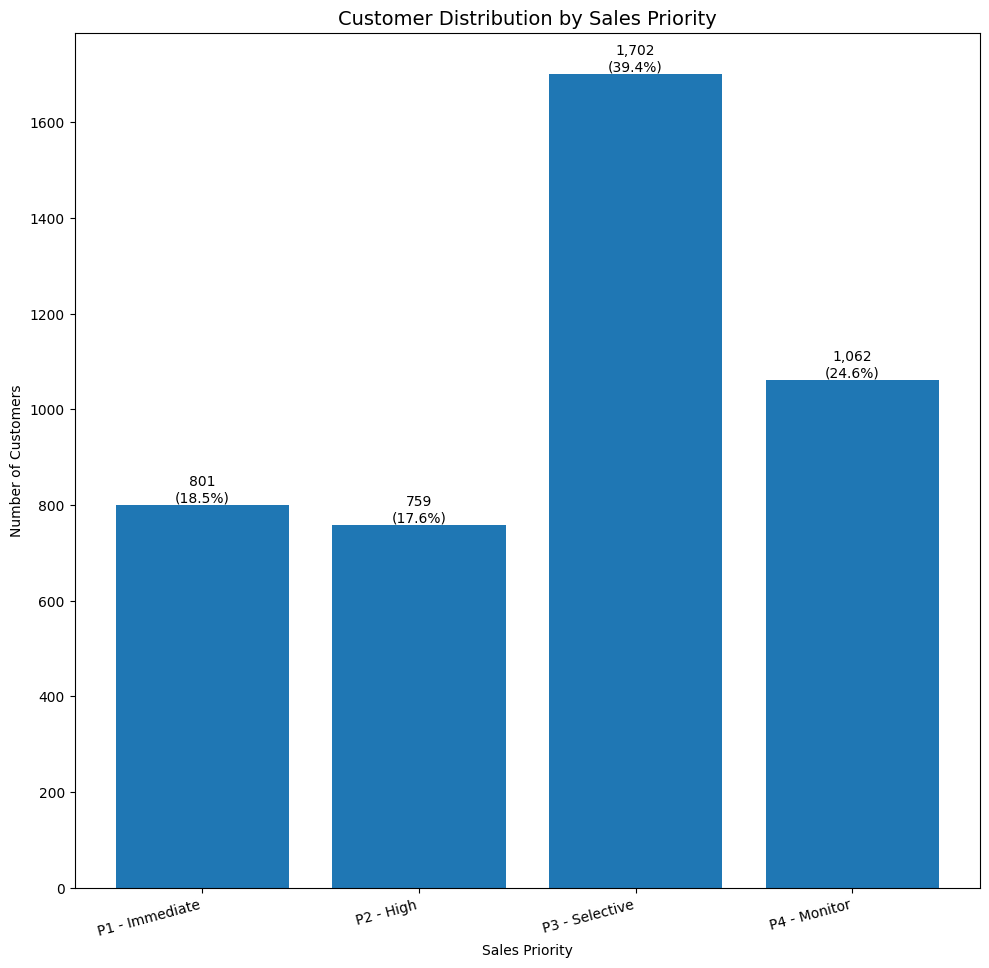

In [40]:
import matplotlib.pyplot as plt

priority_counts = (
    lapse_predictions["sales_priority"]
    .value_counts()
    .reindex([
        "P1 - Immediate",
        "P2 - High",
        "P3 - Selective",
        "P4 - Monitor"
    ])
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    priority_counts.index,
    priority_counts.values
)

plt.title(
    "Customer Distribution by Sales Priority",
    fontsize=14
)
plt.xlabel("Sales Priority")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15, ha="right")

for bar in bars:
    count = int(bar.get_height())
    percentage = count / len(lapse_predictions) * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.subplots_adjust(top=1.88)
plt.savefig(
    "../outputs/charts/sales_priority_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Final Results, Business Implications and Limitations

## 1. Objective and modelling approach

The objective was to identify existing customers who were likely to lapse, enabling the sales team to intervene before customer inactivity becomes prolonged. A lapse was defined as no purchase during the 90 days following a snapshot date.

A rolling-window approach was used, with a 365-day historical observation period and a 90-day outcome period. Four snapshots were created: December 2010, March 2011, June 2011 and September 2011. The first three snapshots were used for model training, while September 2011 was held out for out-of-time testing.

Customer-level features included recency, purchase frequency, monetary value, average order value, product variety, average basket size and customer tenure. Logistic Regression and Random Forest were evaluated against a majority-class baseline.

## 2. Model performance and selection

Random Forest was selected as the final model based on its predictive performance and ability to identify customers likely to lapse.

The decision threshold was selected using the June 2011 validation snapshot. A threshold of 0.40 achieved the highest validation F1-score among the tested thresholds. The final model was then evaluated on the September 2011 test snapshot, which was not used for threshold selection.

At the selected threshold, the model achieved:

- Accuracy: 67.30%
- Precision: 61.74%
- Recall: 92.58%
- F1-score: 74.07%
- ROC-AUC: 76.22%

The model flagged 3,272 of 4,324 test customers (75.67%). Its high recall indicates that it identifies most customers who subsequently lapse, although moderate precision means some flagged customers continue purchasing. The model is therefore a screening tool for potential intervention, not a definitive churn classifier.

## 3. Historically valid customer segmentation

To avoid using information that would not have been available when the September 2011 predictions were made, customer RFM metrics and segments were reconstructed using transactions dated before 1 September 2011.

This historical segmentation covered 5,224 customers. All 4,324 customers in the September prediction cohort received a historical segment, with no missing segment assignments.

Historical RFM segments were combined with the model's lapse predictions to create sales priorities. The final distribution was:

| Sales priority | Customers | Share |
|---|---:|---:|
| P1 – Immediate | 801 | 18.5% |
| P2 – High | 759 | 17.6% |
| P3 – Selective | 1,702 | 39.4% |
| P4 – Monitor | 1,062 | 24.6% |
| **Total** | **4,324** | **100.0%** |

The P1 and P2 groups together contain 1,560 customers (36.1% of the test cohort). These customers form the higher-priority pool for more personalised retention activity.

## 4. Sales prioritisation and business implications

- **P1 – Immediate:** Champions, High-value At Risk and Loyal Customers flagged by the model. These customers warrant personalised sales outreach.
- **P2 – High:** Potential Loyalists and At Risk customers flagged by the model. Targeted reactivation campaigns may be appropriate.
- **P3 – Selective:** Hibernating and Other/Developing customers flagged by the model, along with other lower-priority segments. Lower-cost campaigns are more appropriate than intensive individual outreach.
- **P4 – Monitor:** Customers not flagged by the model and Non-positive Value customers. These customers should be monitored without automatically allocating expensive retention resources.

The average lapse probability is not necessarily highest in P1. P1 and P2 reflect a combination of predicted risk and historical customer value, rather than a simple ranking by probability alone. This distinction is important when sales capacity is limited.

The historical monetary measure used in the priority summary is net monetary value up to 31 August 2011, including product and adjustment transactions. The model's `monetary` feature is different: it is gross purchase value from product invoices in the 365-day observation window. These measures should not be treated as interchangeable.

## 5. Limitations

1. **Definition of lapse:** The target captures 90-day purchase inactivity, not confirmed permanent customer churn.
2. **Limited temporal coverage:** The model uses four snapshots and one out-of-time test period. Further validation across additional periods would improve confidence.
3. **Changing lapse rates:** The training and test periods have different lapse rates, indicating temporal variation in customer behaviour.
4. **False positives:** The model has high recall but moderate precision, so some flagged customers will continue purchasing.
5. **Feature limitations:** The model relies on historical transaction behaviour and does not incorporate customer demographics, marketing interactions or external factors.
6. **Commercial impact:** The analysis does not measure the effectiveness or ROI of retention campaigns. These should be evaluated through controlled outreach experiments.
7. **Revenue versus profitability:** Monetary value represents transaction revenue, not contribution margin or profit, because product cost information is unavailable.
8. **Customer overlap across snapshots:** Customers may appear in both training and test periods because the objective is to predict future lapse for existing customers over time. The evaluation therefore measures temporal prediction performance, not generalisation to entirely unseen customers.

## 6. Overall conclusion

The analysis demonstrates how historical transaction data can be used to identify customers at risk of near-term inactivity and translate predictions into a practical sales-prioritisation framework. Combining lapse probabilities with RFM segments calculated strictly before the prediction date provides a more commercially meaningful and temporally consistent approach than treating all potentially lapsed customers equally.

The resulting framework can help the sales team allocate limited outreach capacity towards customers with elevated lapse risk and stronger historical business value. Its effectiveness should ultimately be assessed through controlled retention campaigns and subsequent measurement of customer response and incremental revenue.
